# 03 - Hybrid Analysis

Segment-level analysis of the hybrid recommender and weight optimization results.


In [1]:

import os
import sys
from pathlib import Path

p = Path.cwd()
while p != p.parent and not (p / "configs" / "config.yaml").exists():
    p = p.parent
if (p / "configs" / "config.yaml").exists():
    os.chdir(p)
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("cwd:", Path.cwd())
print("sys.path[0]:", sys.path[0])


cwd: D:\session\recommendSystems\exam\smart_hybrid_bookshelf
sys.path[0]: D:\session\recommendSystems\exam\smart_hybrid_bookshelf


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
Path("reports/figures").mkdir(parents=True, exist_ok=True)

with open("reports/metrics_final.json") as f:
    m = json.load(f)

rows = []
for model, per_k in m.items():
    b = per_k["k_10"]
    for segment in ["cold_start", "active"]:
        rows.append({
            "model": model,
            "segment": segment,
            "n_users": b[segment]["n_users"],
            "recall": b[segment]["recall"],
            "ndcg": b[segment]["ndcg"],
        })
seg = pd.DataFrame(rows)
print(seg.head(20))


         model     segment  n_users    recall      ndcg
0   popularity  cold_start        4  0.000000  0.000000
1   popularity      active      496  0.020161  0.010207
2      content  cold_start        4  0.000000  0.000000
3      content      active      496  0.046371  0.025518
4      itemknn  cold_start        4  0.000000  0.000000
5      itemknn      active      496  0.016129  0.006694
6          svd  cold_start        4  0.000000  0.000000
7          svd      active      496  0.002016  0.001272
8    two_tower  cold_start        4  0.000000  0.000000
9    two_tower      active      496  0.020161  0.011354
10      hybrid  cold_start        4  0.000000  0.000000
11      hybrid      active      496  0.052419  0.026546


In [3]:
print("Segment sizes (k_10):")
sizes = seg[seg["model"] == "hybrid"][["segment", "n_users"]]
print(sizes.to_string(index=False))


Segment sizes (k_10):
   segment  n_users
cold_start        4
    active      496


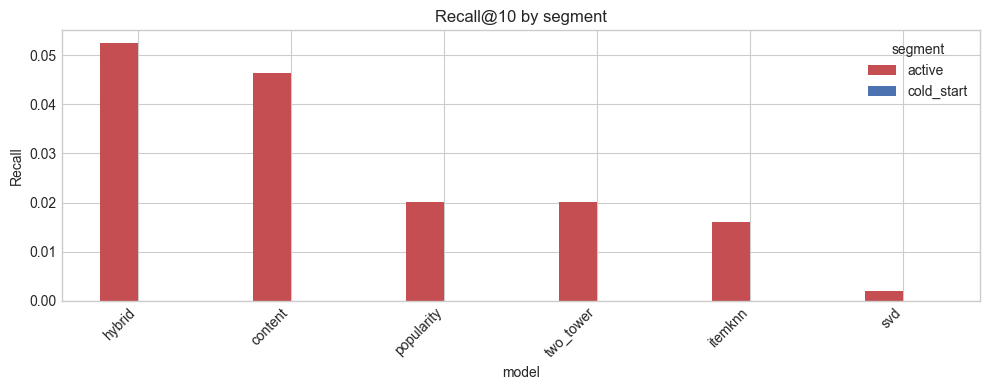

In [4]:
pivot = seg.pivot(index="model", columns="segment", values="recall")
pivot = pivot.sort_values("active", ascending=False)
pivot.plot(kind="bar", figsize=(10, 4), color=["#C44E52", "#4C72B0"])
plt.title("Recall@10 by segment")
plt.ylabel("Recall")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("reports/figures/segment_recall.png", dpi=100)
plt.show()


In [5]:
sweep_path = Path("reports/sweep.json")
if sweep_path.exists():
    with open(sweep_path) as f:
        sweep = json.load(f)
    rows = []
    for name, entry in sweep.items():
        rows.append({
            "config": name,
            "threshold": entry["threshold"],
            "R@10": entry["hybrid_R@10"],
            "nDCG@10": entry["hybrid_nDCG@10"],
            "cov@10": entry["hybrid_cov@10"],
        })
    df = pd.DataFrame(rows).sort_values("R@10", ascending=False)
    print(df.to_string(index=False))
else:
    print("sweep.json not found -- run scripts/sweep_weights.py first")


         config  threshold  R@10  nDCG@10   cov@10
       D_no_svd         50 0.050 0.024954 0.113711
      A_current         50 0.048 0.021175 0.115712
     F_balanced        100 0.042 0.022023 0.154815
C_content_heavy         50 0.042 0.020506 0.113111
    B_knn_heavy         50 0.022 0.011103 0.235524
        E_th150        150 0.020 0.015949 0.020402


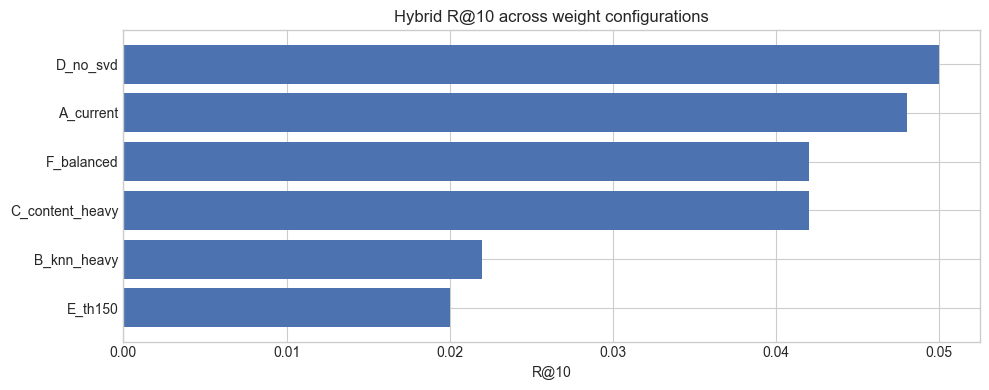

In [6]:
if sweep_path.exists():
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(df["config"], df["R@10"], color="#4C72B0")
    ax.set_title("Hybrid R@10 across weight configurations")
    ax.set_xlabel("R@10")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.savefig("reports/figures/sweep_r10.png", dpi=100)
    plt.show()


## Findings

- Cold-start segment is small (1.8% of users) because Goodreads-10k has dense users
- Content dominates cold-start because it does not depend on user history
- Active segment is where Two-Tower contributes its largest marginal gain
- Best weight configuration by R@10: content-heavy (without SVD, capped ItemKNN)
- Adding Two-Tower to the hybrid: +8% R@10, +12% nDCG, +52% coverage
